In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import xarray as xr

from fast_o3_iv import utils, plots
from fast_o3_iv.modeling.train import DatasetConfig
import fast_o3_iv.bias_correction as bc
import fast_o3_iv.attributable_fraction as af

In [3]:
def make_config(source_id, experiment, start, stop):
    return DatasetConfig(
        source_id=source_id,
        cmip_experiment_id=experiment,
        variable_setname="setC",
        year_range=range(start, stop),
    )

config_hist_original   = make_config("CESM2-WACCM6", "historical", 1975, 2015)
config_hist_synthetic  = make_config("CESM2",        "historical", 1975, 2015)

config_ssp245_original  = make_config("CESM2-WACCM6", "ssp245", 2015, 2055)
config_ssp245_synthetic = make_config("CESM2",        "ssp245", 2015, 2055)

config_ssp585_original  = make_config("CESM2-WACCM6", "ssp585", 2015, 2055)
config_ssp585_synthetic = make_config("CESM2",        "ssp585", 2015, 2055)

In [4]:
file_path = af.return_af_path("targets", config_ssp585_original, "GPR-local") 
ds = xr.open_dataset(file_path)

In [5]:
file_path = bc.return_osdma8_bc_path("targets", config_ssp585_original, "GPR-local")
ds = xr.open_dataset(file_path)

In [6]:
def load_af_window(
    config,
    year_slice,
    *,
    mode="inference",
    model_key="GPR-local",
):
    file_path = af.return_af_path(mode, config, model_key) 
    ds = xr.open_dataset(file_path)
    return ds.sel(time=year_slice)


def concat_members(
    configs,
    year_slice,
    *,
    dim="ensemble_member",
    mode="inference",
    model_key="GPR-local",
):
    if isinstance(mode, str):
        modes = [mode] * len(configs)
    else:
        modes = mode

    datasets = [
        load_af_window(cfg, year_slice, mode=md, model_key=model_key)
        for cfg, md in zip(configs, modes)
    ]
    return xr.concat(datasets, dim=dim)

hist_years = slice("2005", "2014")
fut_years = slice("2045", "2054")

hist_af_sel = concat_members(
    [config_hist_original, config_hist_synthetic],
    hist_years,
)

ssp245_af_sel = concat_members(
    [config_ssp245_original, config_ssp245_synthetic],
    fut_years,
)

ssp585_af_sel = concat_members(
    [config_ssp585_original, config_ssp585_synthetic],
    fut_years,
    mode=["targets", "inference"],
)

In [7]:
def concat_true_then_pred(
    ds,
    true_var="y_true_bc_af",
    pred_var="y_pred_bc_af",
    out_var="y_bc_af",
    member_dim="ensemble_member",
    target_members=20,
):
    true_da = ds[true_var]
    pred_da = ds[pred_var]

    # all dims except ensemble_member
    other_dims = [d for d in true_da.dims if d != member_dim]

    # True if this member has at least one non-NaN value anywhere
    has_true = true_da.notnull().any(dim=other_dims)

    # get positional indices instead of coordinate labels
    true_idx = np.flatnonzero(has_true.values)
    pred_idx = np.flatnonzero(~has_true.values)

    n_true = len(true_idx)
    if n_true > target_members:
        raise ValueError(
            f"{true_var} exists for {n_true} members, which is more than target_members={target_members}."
        )

    n_needed = target_members - n_true
    pred_idx = pred_idx[:n_needed]

    true_part = true_da.isel({member_dim: true_idx})
    pred_part = pred_da.isel({member_dim: pred_idx})

    out = xr.concat([true_part, pred_part], dim=member_dim)
    out.name = 'y_bc_af'

    return out

In [8]:
hist_concat   = concat_true_then_pred(hist_af_sel)
ssp245_concat = concat_true_then_pred(ssp245_af_sel)
ssp585_concat = concat_true_then_pred(ssp585_af_sel)

In [9]:
def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    # y < 0 pushes the colorbar below the axis
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

Text(0.0, 1.0, 'f)')

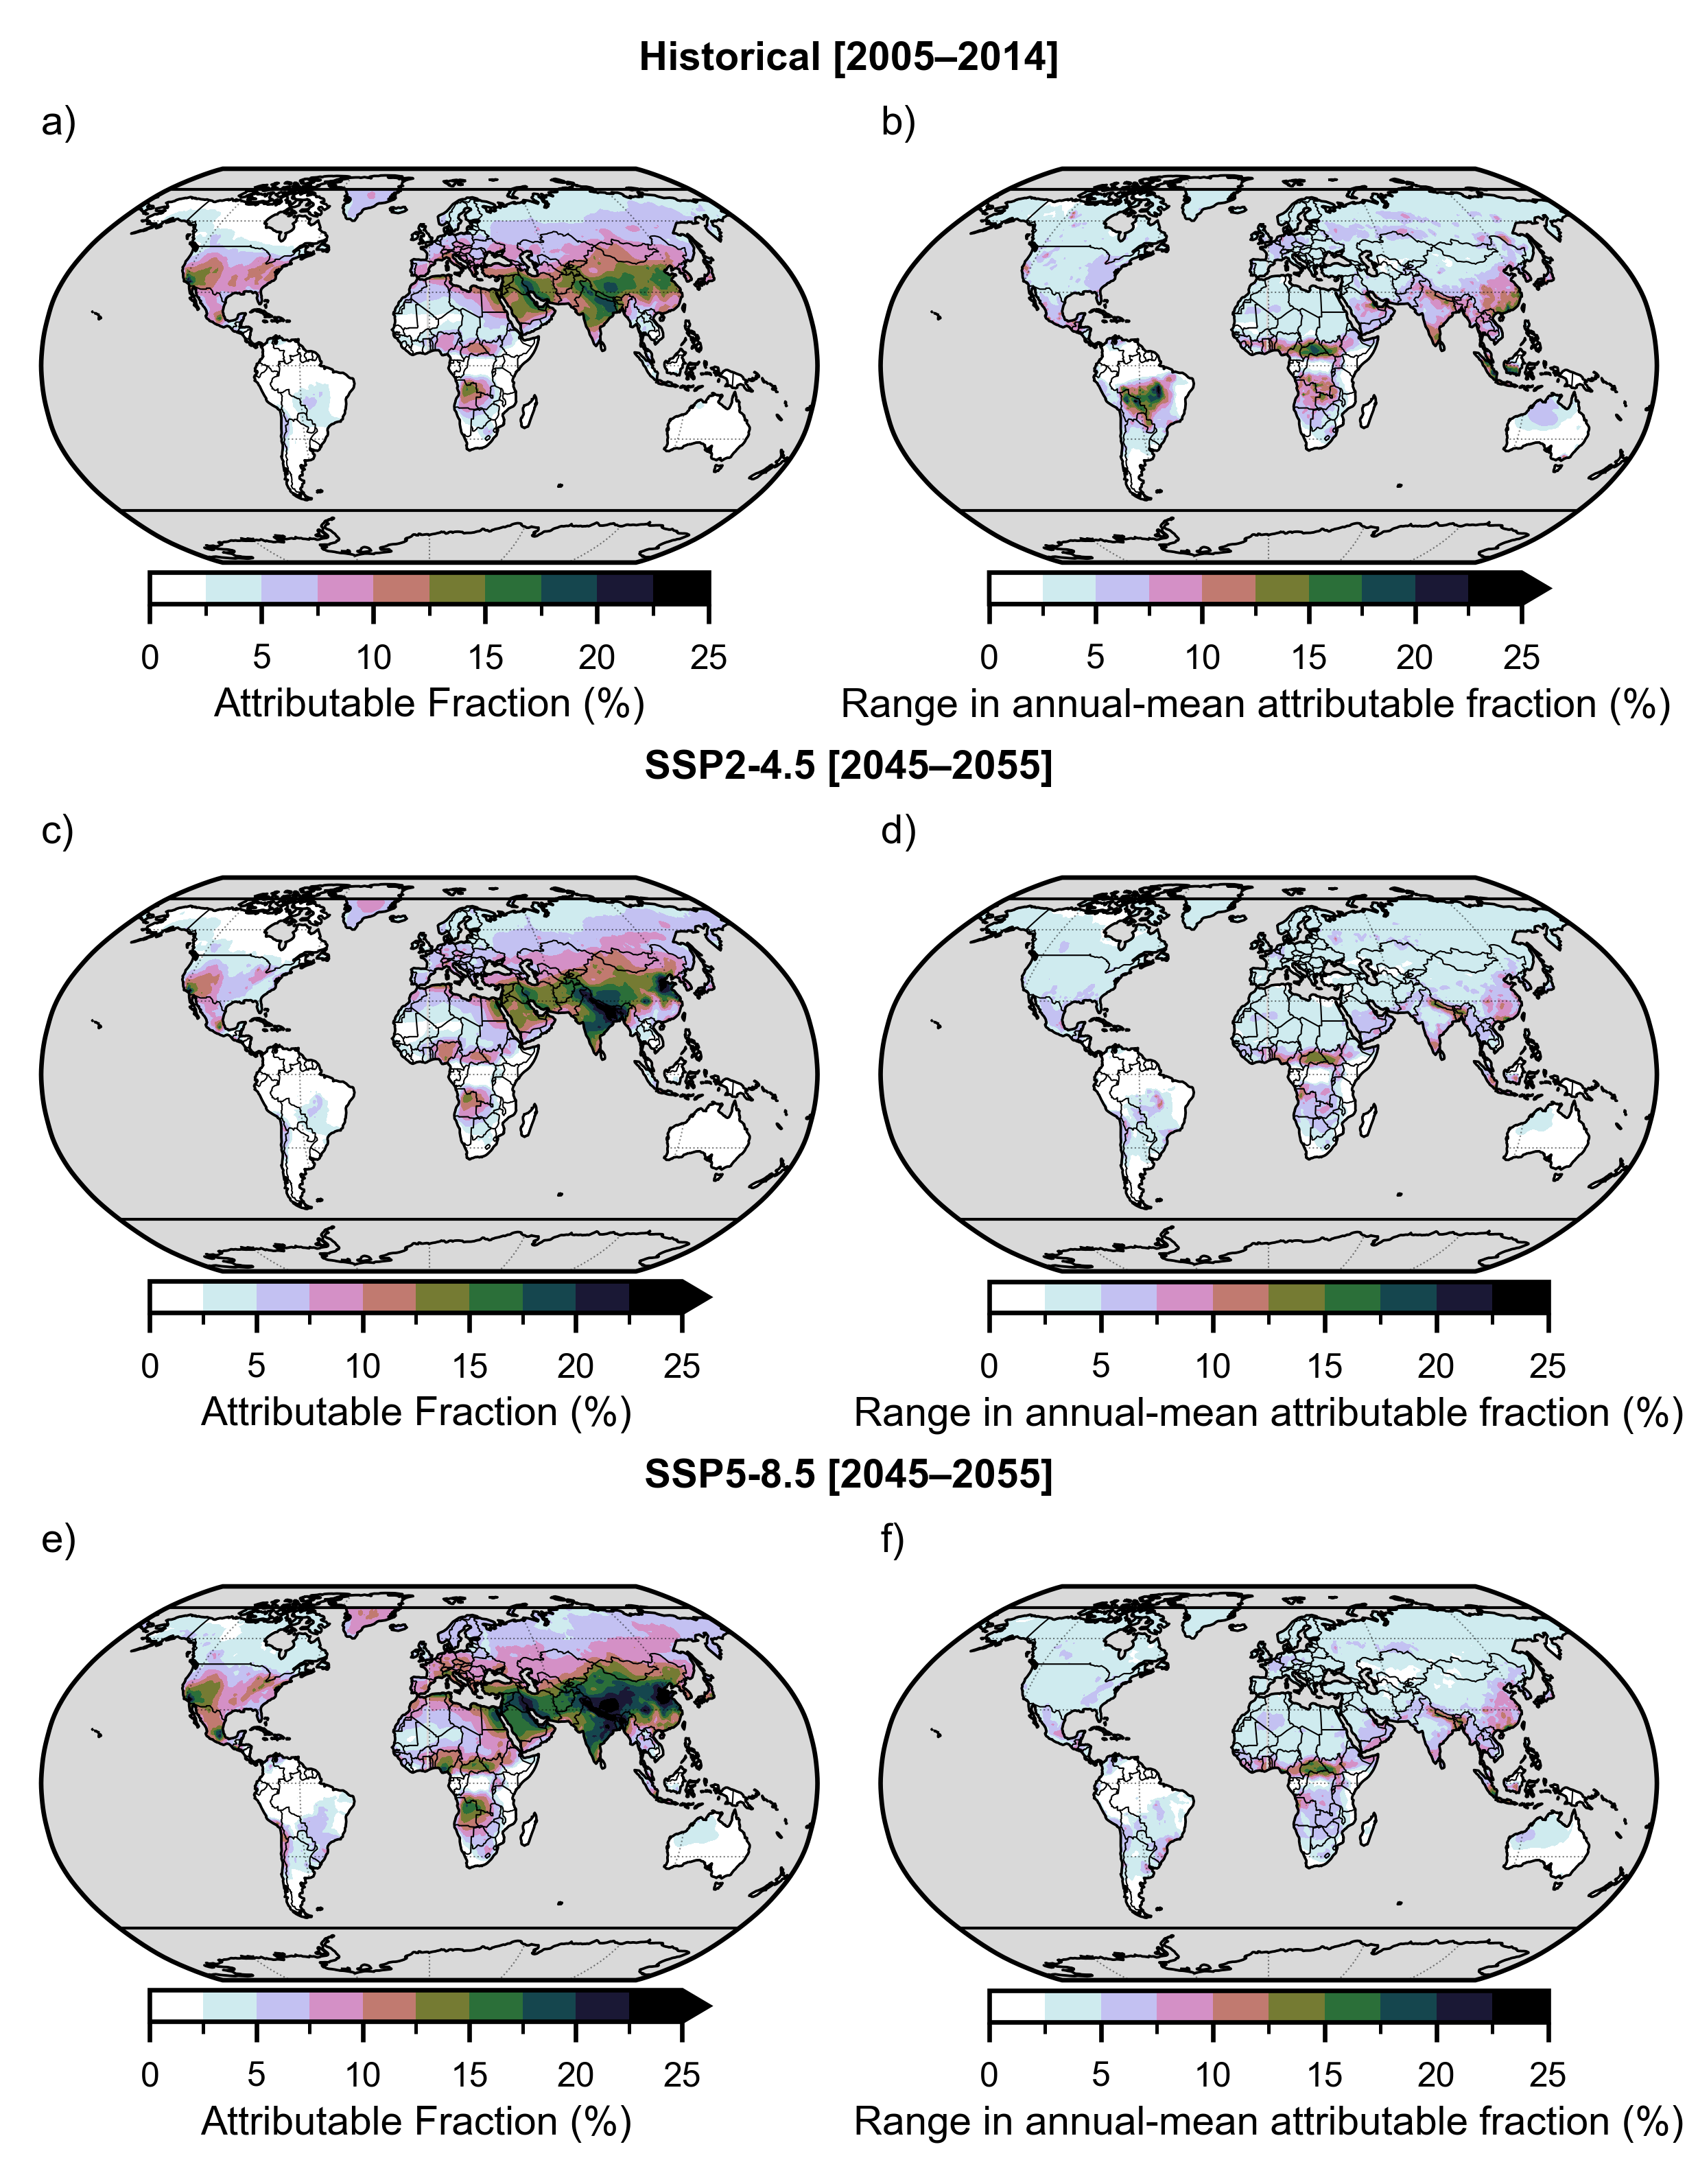

In [10]:

utils.set_matplotlib_font("Arial")

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

fig_width_in = 5
fig_height_in = 5.5

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=600)

gs1 = GridSpec(
    3, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.80, wspace=0.04
)        

proj = ccrs.Robinson(central_longitude=0)

# Row 1
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[0, 1], projection=proj)

# Row 2
ax3 = fig.add_subplot(gs1[1, 0], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

# Row 3
ax5 = fig.add_subplot(gs1[2, 0], projection=proj)
ax6 = fig.add_subplot(gs1[2, 1], projection=proj)

axes = [ax1, ax2, ax3, ax4, ax5, ax6]


for ax in axes:
    style_map(ax)

########################################################
### Attributable Fraction ####
vmax = 25
vmin = 0
step = 2.5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['cubehelix_r'] #cm.hawaii_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF --- ##
z_hist = hist_concat.mean(dim=['ensemble_member', 'time'])
m1 = z_hist.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,         
    add_colorbar=False,
    add_labels=False,
)
add_panel_cbar(fig, ax1, m1, label="Attributable Fraction (%)")

## --- ssp245 AF --- ##
z_ssp245 = ssp245_concat.mean(dim=['ensemble_member', 'time'])
m3 = z_ssp245.plot.contourf(
    ax=ax3,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,         
    add_colorbar=False,
    add_labels=False,
)
add_panel_cbar(fig, ax3, m3, label="Attributable Fraction (%)")

## --- ssp585 AF --- ##
z_ssp585 = ssp585_concat.mean(dim=['ensemble_member', 'time'])
m5 = z_ssp585.plot.contourf(
    ax=ax5,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,         
    add_colorbar=False,
    add_labels=False,
)
add_panel_cbar(fig, ax5, m5, label="Attributable Fraction (%)")


for ax in axes:
    ax.add_feature(
        cfeature.OCEAN,
        facecolor="0.85",
        edgecolor="none",
        zorder=2,
    )

    ax.coastlines(linewidth=0.4, color="black", zorder=3)


##############################################################################
## Attributable Fraction RANGE INTVAR
vmax = 25
vmin = 0
step = 2.5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1


base = mpl.colormaps['cubehelix_r'] #cm.hawaii_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF range --- ##
z1 = (
    hist_concat.max(dim=["ensemble_member", "time"])
    - hist_concat.min(dim=["ensemble_member", "time"])
)

m2 = z1.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

add_panel_cbar(fig, ax2, m2, label="Range in annual-mean attributable fraction (%)")

## --- ssp245 AF range --- ##
z2 = (
    ssp245_concat.max(dim=["ensemble_member", "time"])
    - ssp245_concat.min(dim=["ensemble_member", "time"])
)

m4 = z2.plot.contourf(
    ax=ax4,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

add_panel_cbar(fig, ax4, m4, label="Range in annual-mean attributable fraction (%)")


## --- ssp585 AF range --- ##
z3 = (
    ssp585_concat.max(dim=["ensemble_member", "time"])
    - ssp585_concat.min(dim=["ensemble_member", "time"])
)

m6 = z3.plot.contourf(
    ax=ax6,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

add_panel_cbar(fig, ax6, m6, label="Range in annual-mean attributable fraction (%)")

##############################################################################


#for axes in [ax1, ax2, ax3, ax4, ax5, ax6]:
#    plots.clip_to_obs_lat_band(axes, lat_min=-60, lat_max=75)

lons = np.linspace(-180, 180, 361)

for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
    ax.set_facecolor("0.85")
    ax.plot(
        lons, np.full_like(lons, 75),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )
    ax.plot(
        lons, np.full_like(lons, -60),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )

# centered row titles
row1_left, row1_right = ax1.get_position(), ax2.get_position()
row2_left, row2_right = ax3.get_position(), ax4.get_position()
row3_left, row3_right = ax5.get_position(), ax6.get_position()

x_row1 = 0.5 * (row1_left.x0 + row1_right.x1)
x_row2 = 0.5 * (row2_left.x0 + row2_right.x1)
x_row3 = 0.5 * (row3_left.x0 + row3_right.x1)

y_row1 = row1_left.y1 + 0.04
y_row2 = row2_left.y1 + 0.04
y_row3 = row3_left.y1 + 0.04

fig.text(
    x_row1, y_row1, "Historical [2005–2014]",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

fig.text(
    x_row2, y_row2, "SSP2-4.5 [2045–2055]",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

fig.text(
    x_row3, y_row3, "SSP5-8.5 [2045–2055]",
    ha="center", va="bottom", fontsize=7, color="black", fontweight='bold'
)

ax1.set_title("a)", loc="left", fontsize=7)
ax2.set_title("b)", loc="left", fontsize=7)

ax3.set_title("c)", loc="left", fontsize=7)
ax4.set_title("d)", loc="left", fontsize=7)

ax5.set_title("e)", loc="left", fontsize=7)
ax6.set_title("f)", loc="left", fontsize=7)



In [11]:
####################################
# Calculation of area-weighted ensemble-mean AF in populated grid cells under each scenario

def calc_gwmean_AF(z_ds):
    z_ds = z_ds.to_dataset()
    z_ds = utils.add_aux_data(z_ds)
    mask = z_ds["population_density"] > 1
    z_mean = utils.global_wmean(z_ds, 'y_bc_af', spatial_dims=("lat", "lon"), mask=mask)
    return z_mean

z_hist_mean = calc_gwmean_AF(z_hist)
print("Historical Attributable Fraction (global area-weighted mean in populated grid cells)")
print(z_hist_mean.values)

z_ssp245_mean = calc_gwmean_AF(z_ssp245)
print("SSP245 Attributable Fraction (global area-weighted mean in populated grid cells)")
print(z_ssp245_mean.values)

z_ssp585_mean = calc_gwmean_AF(z_ssp585)
print("SSP585 Attributable Fraction (global area-weighted mean in populated grid cells)")
print(z_ssp585_mean.values)


Historical Attributable Fraction (global area-weighted mean in populated grid cells)
5.495222805706727
SSP245 Attributable Fraction (global area-weighted mean in populated grid cells)
5.309417060825049
SSP585 Attributable Fraction (global area-weighted mean in populated grid cells)
7.365909772495028


In [16]:
z1_max = calc_gwmean_AF(hist_concat.max(dim=["ensemble_member", "time"]))
z1_min = calc_gwmean_AF(hist_concat.min(dim=["ensemble_member", "time"]))
z1_range = calc_gwmean_AF(z1)
print("Historical Attributable Fraction Range (global area-weighted mean in populated grid cells)")
print(f"range: {z1_range.values}")
print(f"max: {z1_max.values}")
print(f"min: {z1_min.values}")

z2_max = calc_gwmean_AF(ssp245_concat.max(dim=["ensemble_member", "time"]))
z2_min = calc_gwmean_AF(ssp245_concat.min(dim=["ensemble_member", "time"]))
z2_mean = calc_gwmean_AF(z2)
print("SSP245 Attributable Fraction Range(global area-weighted mean in populated grid cells)")
print(f"range: {z2_mean.values}")
print(f"max: {z2_max.values}")
print(f"min: {z2_min.values}")

z3_max = calc_gwmean_AF(ssp585_concat.max(dim=["ensemble_member", "time"]))
z3_min = calc_gwmean_AF(ssp585_concat.min(dim=["ensemble_member", "time"]))
z3_mean = calc_gwmean_AF(z3)
print("SSP585 Attributable Fraction Range (global area-weighted mean in populated grid cells)")
print(f"range: {z3_mean.values}")
print(f"max: {z3_max.values}")
print(f"min: {z3_min.values}")

Historical Attributable Fraction Range (global area-weighted mean in populated grid cells)
range: 4.569142641500566
max: 8.053518642840821
min: 3.484376001340258
SSP245 Attributable Fraction Range(global area-weighted mean in populated grid cells)
range: 3.5709391682787226
max: 7.1543039614482735
min: 3.583364793169547
SSP585 Attributable Fraction Range (global area-weighted mean in populated grid cells)
range: 4.032087532730248
max: 9.414554343273267
min: 5.382466810543017


In [13]:
# decadal mean:
#z = (
#    hist_concat.mean(dim='time').max(dim="ensemble_member")
#    - hist_concat.mean(dim='time').min(dim="ensemble_member")
#)
